In [1]:
import dill
import scanpy as sc
import anndata as ad
import muon as mu
import os
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
import pandas
import pyranges
# Set stderr to null to avoid strange messages from ray
import sys
_stderr = sys.stderr
null = open(os.devnull,'wb')

import seaborn as sns

from scenicplus.scenicplus_class import SCENICPLUS, create_SCENICPLUS_object
from scenicplus.preprocessing.filtering import *
from scenicplus.utils import region_names_to_coordinates
from scenicplus.eregulon_enrichment import make_rankings

from scenicplus.wrappers.run_scenicplus import run_scenicplus

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/')
from scenicplus_modified_dotplot import *
from single_cell_utils import *

sys.path.append('/nfs/casm/team215mg/users/od5/scripts/GRNcompare/')
from GRNcompare import *

import pybedtools

In [2]:
## Set up work directory
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/scenicplus/tf_pilot/batch1/ipsc/'

In [3]:
## And output directory
output_p = work_dir + 'scenicplus_full/'
os.makedirs(output_p, exist_ok=True)

In [4]:
contexts = ['full']
seeds = range(1,21)

In [5]:
## Reading in eRegulon (filtered) metadata
grns_dict = {}
for context in contexts:
    for i in seeds:
        fname = (work_dir + 'scenicplus_' + context + '/seed_' + str(i) + '/scplus_eRegulon_metadata_filtered.csv')
        if os.path.isfile(fname):
            df = import_scplus(pd.read_csv(fname, index_col=0))
            df['seed'] = i
            df['context'] = context
            grns_dict[(context + '_' + str(i))] = df

In [6]:
for k in grns_dict.keys():
    print(k)
    print(grns_dict[k].shape[0])

full_1
4945
full_2
12942
full_3
9966
full_4
11838
full_5
9910
full_6
8257
full_7
7674
full_8
10464
full_9
8995
full_10
9873
full_11
10543
full_12
11592
full_13
7693
full_14
8987
full_15
9591
full_16
9866
full_17
8950
full_18
12476
full_19
8003
full_20
11242


In [7]:
## Combining into consensus non-redundant grn
grn_comb = combine_grns([grns_dict[k][['Triplet','TF','Region','Gene','TF2G_sign','R2G_sign','TF2R','R2G','TF2G']] for k in grns_dict.keys()])

In [8]:
grn_comb

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G
BACH2#chr5:175590310-175590810#HRH2,BACH2#chr5:175590310-175590810#HRH2,BACH2,chr5:175590310-175590810,HRH2,+,+,BACH2#chr5:175590310-175590810,chr5:175590310-175590810#HRH2,BACH2#HRH2
BACH2#chr5:175652996-175653496#HRH2,BACH2#chr5:175652996-175653496#HRH2,BACH2,chr5:175652996-175653496,HRH2,+,+,BACH2#chr5:175652996-175653496,chr5:175652996-175653496#HRH2,BACH2#HRH2
BACH2#chr6:17417671-17418171#CAP2,BACH2#chr6:17417671-17418171#CAP2,BACH2,chr6:17417671-17418171,CAP2,+,+,BACH2#chr6:17417671-17418171,chr6:17417671-17418171#CAP2,BACH2#CAP2
BACH2#chr1:33244010-33244510#PHC2,BACH2#chr1:33244010-33244510#PHC2,BACH2,chr1:33244010-33244510,PHC2,+,+,BACH2#chr1:33244010-33244510,chr1:33244010-33244510#PHC2,BACH2#PHC2
BACH2#chr7:2399826-2400326#LFNG,BACH2#chr7:2399826-2400326#LFNG,BACH2,chr7:2399826-2400326,LFNG,+,+,BACH2#chr7:2399826-2400326,chr7:2399826-2400326#LFNG,BACH2#LFNG
...,...,...,...,...,...,...,...,...,...
ZSCAN29#chr15:90265431-90265931#GDPGP1,ZSCAN29#chr15:90265431-90265931#GDPGP1,ZSCAN29,chr15:90265431-90265931,GDPGP1,-,+,ZSCAN29#chr15:90265431-90265931,chr15:90265431-90265931#GDPGP1,ZSCAN29#GDPGP1
ZSCAN29#chr15:90387852-90388352#GDPGP1,ZSCAN29#chr15:90387852-90388352#GDPGP1,ZSCAN29,chr15:90387852-90388352,GDPGP1,-,+,ZSCAN29#chr15:90387852-90388352,chr15:90387852-90388352#GDPGP1,ZSCAN29#GDPGP1
ZSCAN29#chr14:80954715-80955215#TSHR,ZSCAN29#chr14:80954715-80955215#TSHR,ZSCAN29,chr14:80954715-80955215,TSHR,-,+,ZSCAN29#chr14:80954715-80955215,chr14:80954715-80955215#TSHR,ZSCAN29#TSHR
ZSCAN29#chr5:1004839-1005339#BRD9,ZSCAN29#chr5:1004839-1005339#BRD9,ZSCAN29,chr5:1004839-1005339,BRD9,-,+,ZSCAN29#chr5:1004839-1005339,chr5:1004839-1005339#BRD9,ZSCAN29#BRD9


In [9]:
## Next, examining how often each connection occurs in each context
grn_comb_redundant = pd.concat([grns_dict[k] for k in grns_dict.keys()])

for context in contexts:
    ## Subset to context
    grn_comb_redundant_cont = grn_comb_redundant[grn_comb_redundant['context']==context].copy()

    ## And count occurrence of edges
    triplet_counts = grn_comb_redundant_cont['Triplet'].value_counts().to_frame(('n_called_triplet_' + context)) 
    R2G_counts = grn_comb_redundant_cont[['R2G', 'seed']].drop_duplicates()['R2G'].value_counts().to_frame(('n_called_R2G_' + context)).reset_index(names='R2G')
    TF2R_counts = grn_comb_redundant_cont[['TF2R', 'seed']].drop_duplicates()['TF2R'].value_counts().to_frame(('n_called_TF2R_'+ context)).reset_index(names='TF2R')
    TF2G_counts = grn_comb_redundant_cont[['TF2G', 'seed']].drop_duplicates()['TF2G'].value_counts().to_frame(('n_called_TF2G_'+ context)).reset_index(names='TF2G')
    tf_counts = grn_comb_redundant_cont[['TF', 'seed']].drop_duplicates()['TF'].value_counts().to_frame(('n_called_tf_'+ context)).reset_index(names='TF')

    ## Add stats to the non-redundant dataframe:
    grn_comb = pd.merge(grn_comb, triplet_counts, left_index=True, right_index=True, how='left')
    
    x = pd.merge(grn_comb, R2G_counts, on='R2G', how='left')
    x = pd.merge(x, TF2G_counts, on='TF2G', how='left')
    x = pd.merge(x, TF2R_counts, on='TF2R', how='left')
    x = pd.merge(x, tf_counts, on='TF', how='left')
    x.index = grn_comb.index.copy()
    grn_comb = x.copy()
    grn_comb.fillna(0, inplace = True)  

count    92028.000000
mean         2.106489
std          2.820048
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         20.000000
Name: n_called_triplet_full, dtype: float64


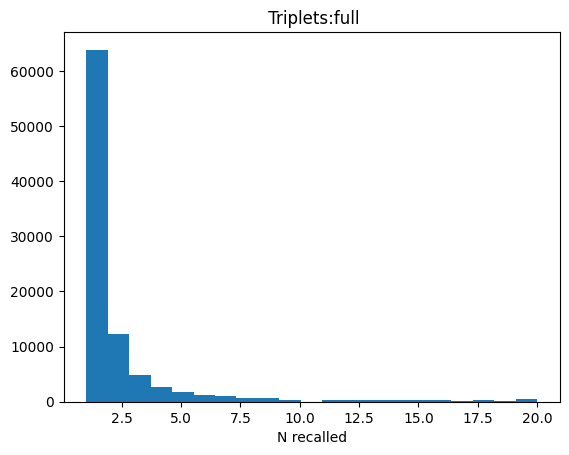

In [10]:
for context in contexts:
    print(grn_comb[('n_called_triplet_' + context)].describe())
    plt.hist(grn_comb[('n_called_triplet_' + context)], bins=len(seeds) + 1)
    plt.title(' Triplets:' + context)
    plt.xlabel('N recalled')
    plt.show()

count    43433.000000
mean         3.744043
std          4.043349
min          1.000000
25%          1.000000
50%          2.000000
75%          5.000000
max         20.000000
Name: n_called_R2G_full, dtype: float64


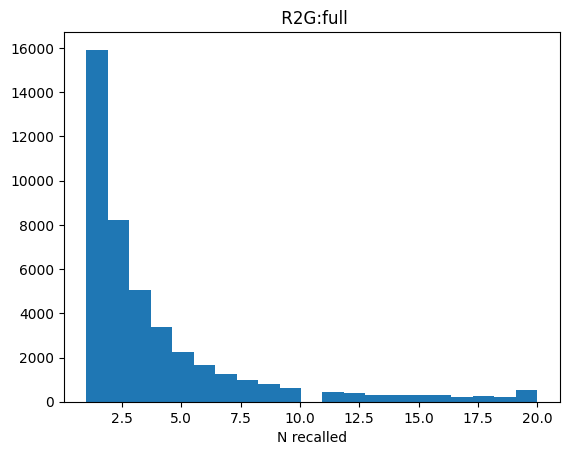

In [11]:
for context in contexts:
    df_sub = grn_comb[['R2G', ('n_called_R2G_' + context)]].drop_duplicates()
    print(df_sub[('n_called_R2G_' + context)].describe())
    plt.hist(df_sub[('n_called_R2G_' + context)], bins=len(seeds) + 1)
    plt.title(' R2G:' + context)
    plt.xlabel('N recalled')
    plt.show()

count    57929.000000
mean         2.230282
std          2.981333
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         20.000000
Name: n_called_TF2G_full, dtype: float64


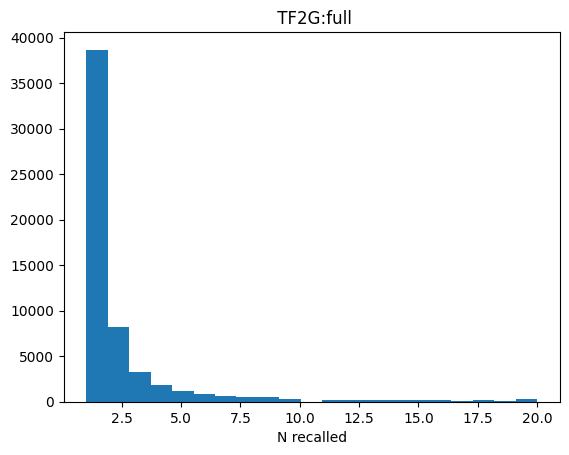

In [12]:
for context in contexts:
    df_sub = grn_comb[['TF2G', ('n_called_TF2G_' + context)]].drop_duplicates()
    print(df_sub[('n_called_TF2G_' + context)].describe())
    plt.hist(df_sub[('n_called_TF2G_' + context)], bins=len(seeds) + 1)
    plt.title(' TF2G:' + context)
    plt.xlabel('N recalled')
    plt.show()

count    82261.000000
mean         2.186382
std          2.899186
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         20.000000
Name: n_called_TF2R_full, dtype: float64


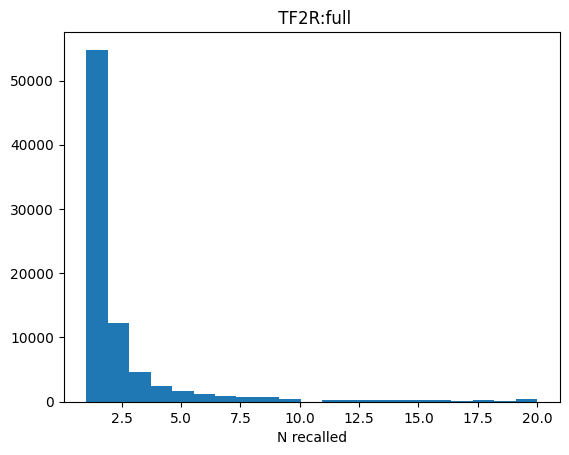

In [13]:
for context in contexts:
    df_sub = grn_comb[['TF2R', ('n_called_TF2R_' + context)]].drop_duplicates()
    print(df_sub[('n_called_TF2R_' + context)].describe())
    plt.hist(df_sub[('n_called_TF2R_' + context)], bins=len(seeds) + 1)
    plt.title(' TF2R:' + context)
    plt.xlabel('N recalled')
    plt.show()

In [14]:
minN = 5
grn_comb_high_conf = grn_comb[(grn_comb['n_called_triplet_full']>=minN)]

In [15]:
grn_comb_high_conf

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full
ARID3A#chr11:107916525-107917025#RAB39A,ARID3A#chr11:107916525-107917025#RAB39A,ARID3A,chr11:107916525-107917025,RAB39A,-,+,ARID3A#chr11:107916525-107917025,chr11:107916525-107917025#RAB39A,ARID3A#RAB39A,6,6,6,6,12
ARID3A#chr11:64356450-64356950#GPR137,ARID3A#chr11:64356450-64356950#GPR137,ARID3A,chr11:64356450-64356950,GPR137,+,+,ARID3A#chr11:64356450-64356950,chr11:64356450-64356950#GPR137,ARID3A#GPR137,7,9,7,7,12
ARID3A#chr12:2691652-2692152#ITFG2,ARID3A#chr12:2691652-2692152#ITFG2,ARID3A,chr12:2691652-2692152,ITFG2,-,+,ARID3A#chr12:2691652-2692152,chr12:2691652-2692152#ITFG2,ARID3A#ITFG2,5,9,6,5,12
ARID3A#chr12:2944628-2945128#ITFG2,ARID3A#chr12:2944628-2945128#ITFG2,ARID3A,chr12:2944628-2945128,ITFG2,-,+,ARID3A#chr12:2944628-2945128,chr12:2944628-2945128#ITFG2,ARID3A#ITFG2,6,6,6,6,12
ARID3A#chr12:57456037-57456537#INHBE,ARID3A#chr12:57456037-57456537#INHBE,ARID3A,chr12:57456037-57456537,INHBE,+,+,ARID3A#chr12:57456037-57456537,chr12:57456037-57456537#INHBE,ARID3A#INHBE,5,5,7,5,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10,chrX:48958188-48958688,TFE3,+,+,ZSCAN10#chrX:48958188-48958688,chrX:48958188-48958688#TFE3,ZSCAN10#TFE3,9,11,9,10,19
ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10,chrX:49002006-49002506,TFE3,+,+,ZSCAN10#chrX:49002006-49002506,chrX:49002006-49002506#TFE3,ZSCAN10#TFE3,7,8,9,7,19
ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10,chrX:49073807-49074307,TFE3,+,+,ZSCAN10#chrX:49073807-49074307,chrX:49073807-49074307#TFE3,ZSCAN10#TFE3,7,7,9,7,19
ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10,chrX:49101053-49101553,TFE3,+,+,ZSCAN10#chrX:49101053-49101553,chrX:49101053-49101553#TFE3,ZSCAN10#TFE3,5,5,9,5,19


In [16]:
len(grn_comb_high_conf['TF'].unique())

103

In [17]:
len(grn_comb_high_conf['Region'].unique())

5444

In [18]:
len(grn_comb_high_conf['Gene'].unique())

3539

In [19]:
## Number of edges recalled as GRN number
grn_stats_dict = {}
for context in contexts:
    print(context)
    dfs = []
    counter = 0
    for k in grns_dict.keys():
        if k.startswith(context):
            n = int(k.replace((context + '_'), ''))
            print(n)
            grn_list = []
            for i in range(1, n + 1):  
                key = (context + '_' + str(i))
                if key in grns_dict.keys():
                    grn_list.append(grns_dict[key])        
            grn_comb_stats = combine_grns(grn_list)
            counter +=1
            df = pd.DataFrame(
                {'n_GRN': counter,
                 'n_TFs': len(grn_comb_stats['TF'].unique()),
                 'n_Regions': len(grn_comb_stats['Region'].unique()),
                 'n_Genes': len(grn_comb_stats['Gene'].unique()),
                 'n_Triplets': len(grn_comb_stats['Triplet'].unique()),
                 'n_TF2G': len(grn_comb_stats['TF2G'].unique()),
                 'n_TF2R': len(grn_comb_stats['TF2R'].unique()),
                 'n_R2G': len(grn_comb_stats['R2G'].unique())},
                index=pd.Index([n]))
            dfs.append(df)
    grn_stats_dict[context] = pd.concat(dfs)

full
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20


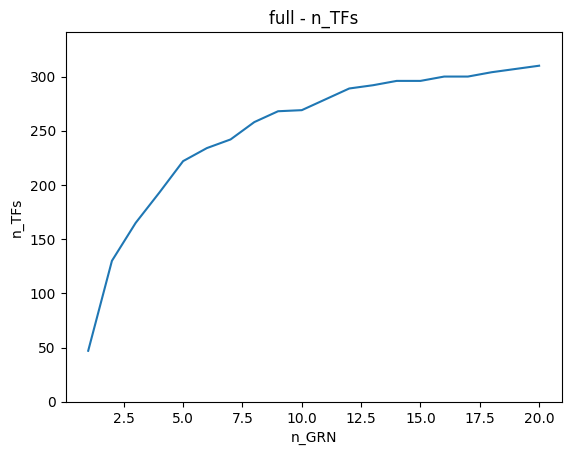

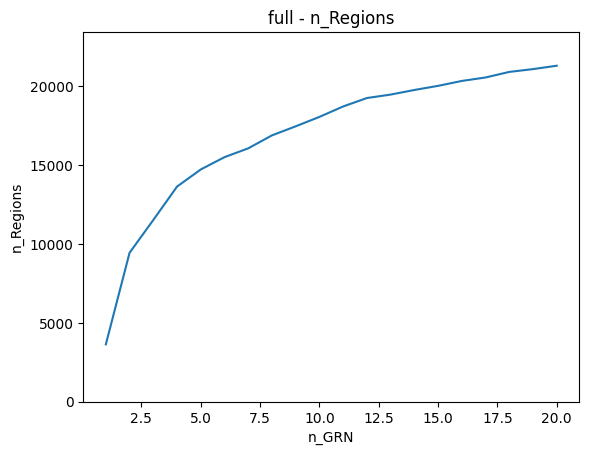

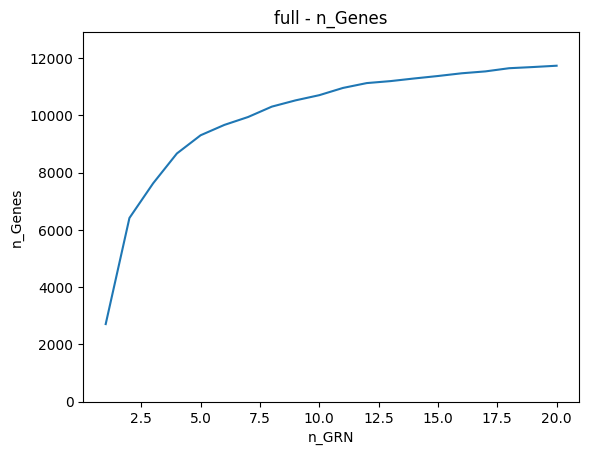

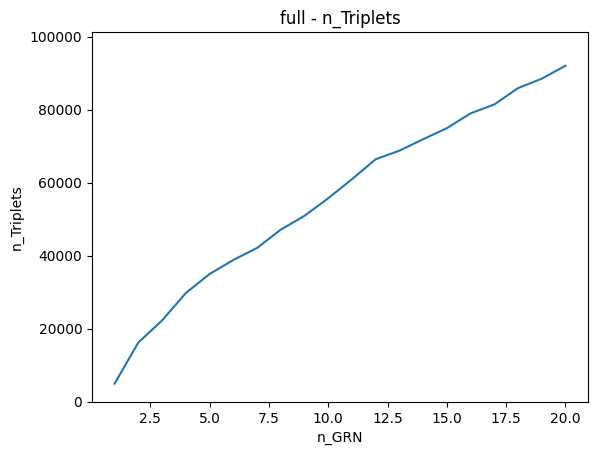

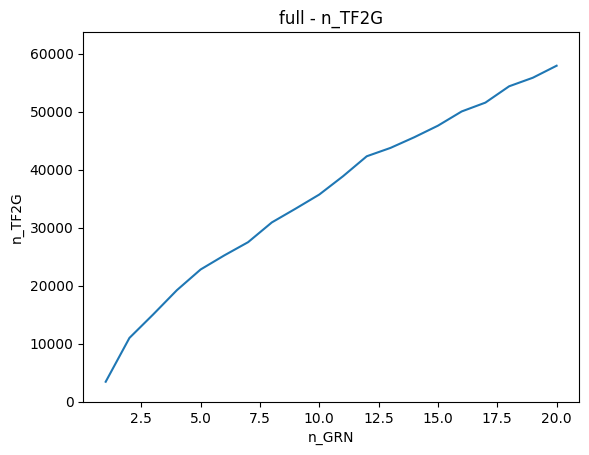

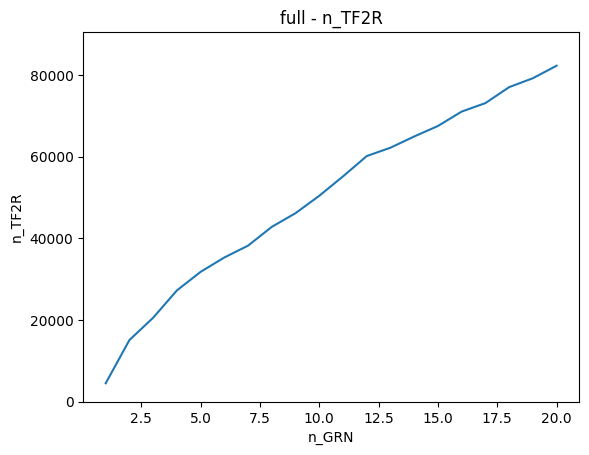

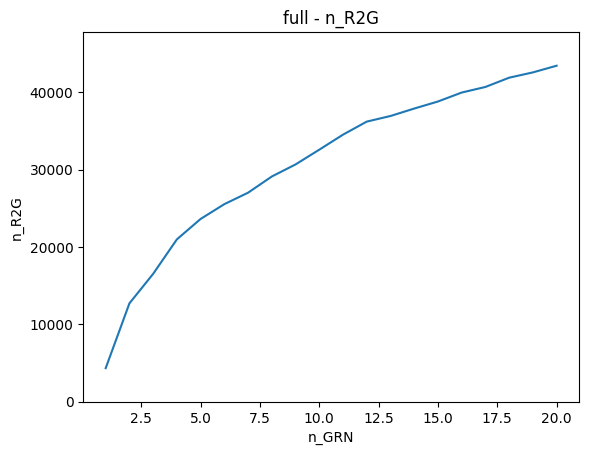

In [20]:
for context in contexts:
    for x in ['n_TFs', 'n_Regions', 'n_Genes', 'n_Triplets', 'n_TF2G', 'n_TF2R','n_R2G']:
        sns.lineplot(grn_stats_dict[context], x='n_GRN', y=x)
        plt.ylim([0, (max(grn_stats_dict[context][x]) +  0.1 * max(grn_stats_dict[context][x])) ])
        plt.title((context + ' - ' + x))
        plt.show()

In [21]:
def jaccard_index(set1, set2):
    set1 = set(set1)
    set2 = set(set2)
    intersection = set1 & set2
    union = set1 | set2
    if not union:
        return 0  # Avoid division by zero if both sets are empty
    return len(intersection) / len(union)

In [22]:
## Pairwise comparisons
dfs = []
for i in grns_dict.keys():
    jis = []
    js = []
    for j in grns_dict.keys(): 
        ji = jaccard_index(grns_dict[i]['Triplet'], grns_dict[j]['Triplet'])
        jis.append(ji)
        js.append(j)
    df = pd.DataFrame({
        'i': i,
        'j': js,
        'JI': jis
    })
    dfs.append(df)
triplet_ji_df = pd.concat(dfs)

In [23]:
triplet_ji_df.pivot(index='i', columns='j', values='JI')

j,full_1,full_10,full_11,full_12,full_13,full_14,full_15,full_16,full_17,full_18,full_19,full_2,full_20,full_3,full_4,full_5,full_6,full_7,full_8,full_9
i,,,,,,,,,,,,,,,,,,,,
full_1,1.000000,0.116149,0.121425,0.121305,0.168238,0.152357,0.118154,0.149565,0.198671,0.118380,0.111321,0.103046,0.132037,0.134434,0.126678,0.133450,0.169146,0.150424,0.126554,0.161860
full_10,0.116149,1.000000,0.127146,0.123469,0.155658,0.131374,0.122621,0.124281,0.135489,0.153675,0.124772,0.134567,0.134361,0.162964,0.109402,0.165557,0.153748,0.128570,0.130901,0.156694
full_11,0.121425,0.127146,1.000000,0.110693,0.139750,0.119134,0.143068,0.126325,0.129505,0.131711,0.111871,0.137619,0.126713,0.162378,0.109893,0.126515,0.134444,0.149410,0.139146,0.130868
full_12,0.121305,0.123469,0.110693,1.000000,0.179872,0.163378,0.130242,0.124397,0.166695,0.158452,0.128744,0.129558,0.171395,0.176297,0.113329,0.142994,0.156230,0.126864,0.128877,0.140933
full_13,0.168238,0.155658,0.139750,0.179872,1.000000,0.187780,0.136507,0.149751,0.183124,0.152053,0.142275,0.152471,0.171865,0.178445,0.142966,0.157864,0.207053,0.165138,0.159525,0.192426
full_14,0.152357,0.131374,0.119134,0.163378,0.187780,1.000000,0.157219,0.128517,0.176042,0.161166,0.134558,0.150766,0.173376,0.181093,0.115545,0.141261,0.165923,0.138046,0.157729,0.155656
full_15,0.118154,0.122621,0.143068,0.130242,0.136507,0.157219,1.000000,0.125398,0.164928,0.182266,0.161934,0.165038,0.163660,0.175724,0.160897,0.129772,0.153195,0.164823,0.142410,0.166217
full_16,0.149565,0.124281,0.126325,0.124397,0.149751,0.128517,0.125398,1.000000,0.151812,0.124522,0.107880,0.131967,0.136488,0.138135,0.109838,0.143055,0.144490,0.130373,0.132149,0.169312
full_17,0.198671,0.135489,0.129505,0.166695,0.183124,0.176042,0.164928,0.151812,1.000000,0.151069,0.139697,0.151362,0.176416,0.176441,0.147304,0.148809,0.170942,0.164064,0.140859,0.167230


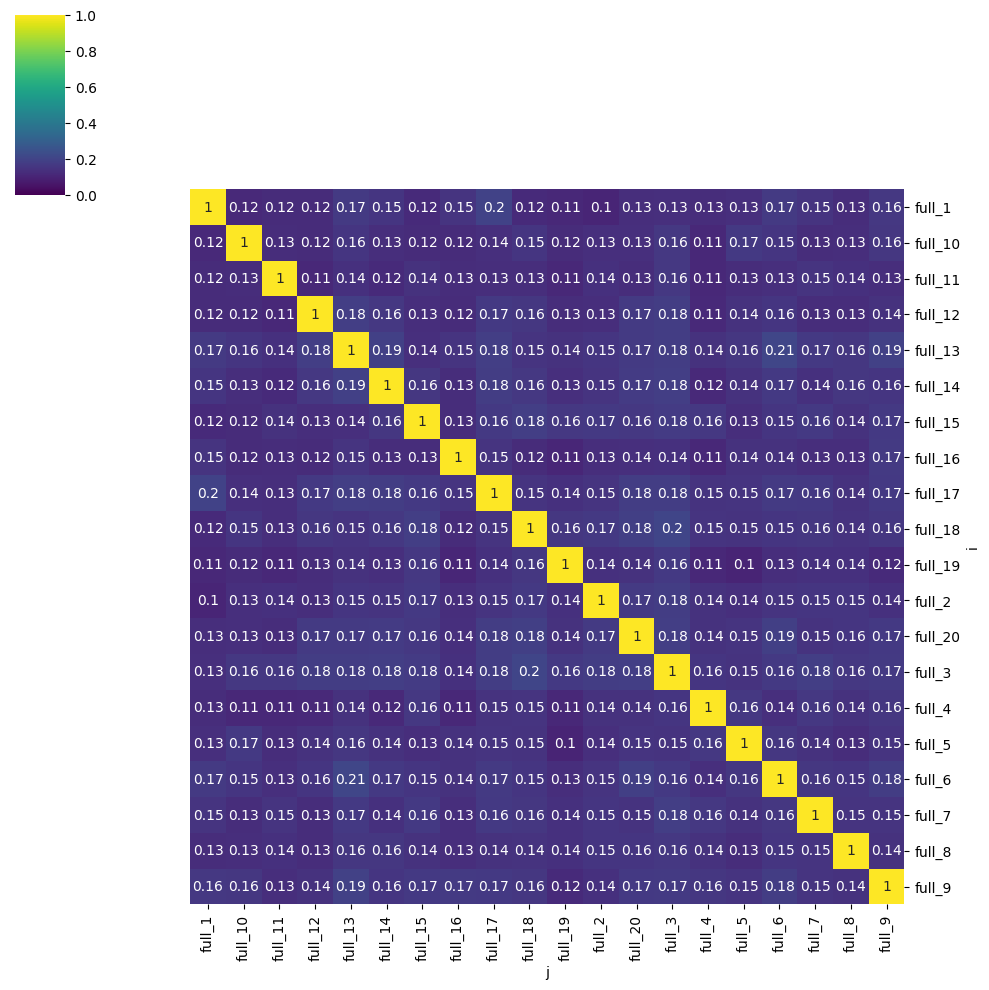

In [24]:
sns.clustermap(triplet_ji_df.pivot(index='i', columns='j', values='JI'), col_cluster=False, row_cluster=False, annot=True, vmin=0, vmax=1, cmap='viridis')

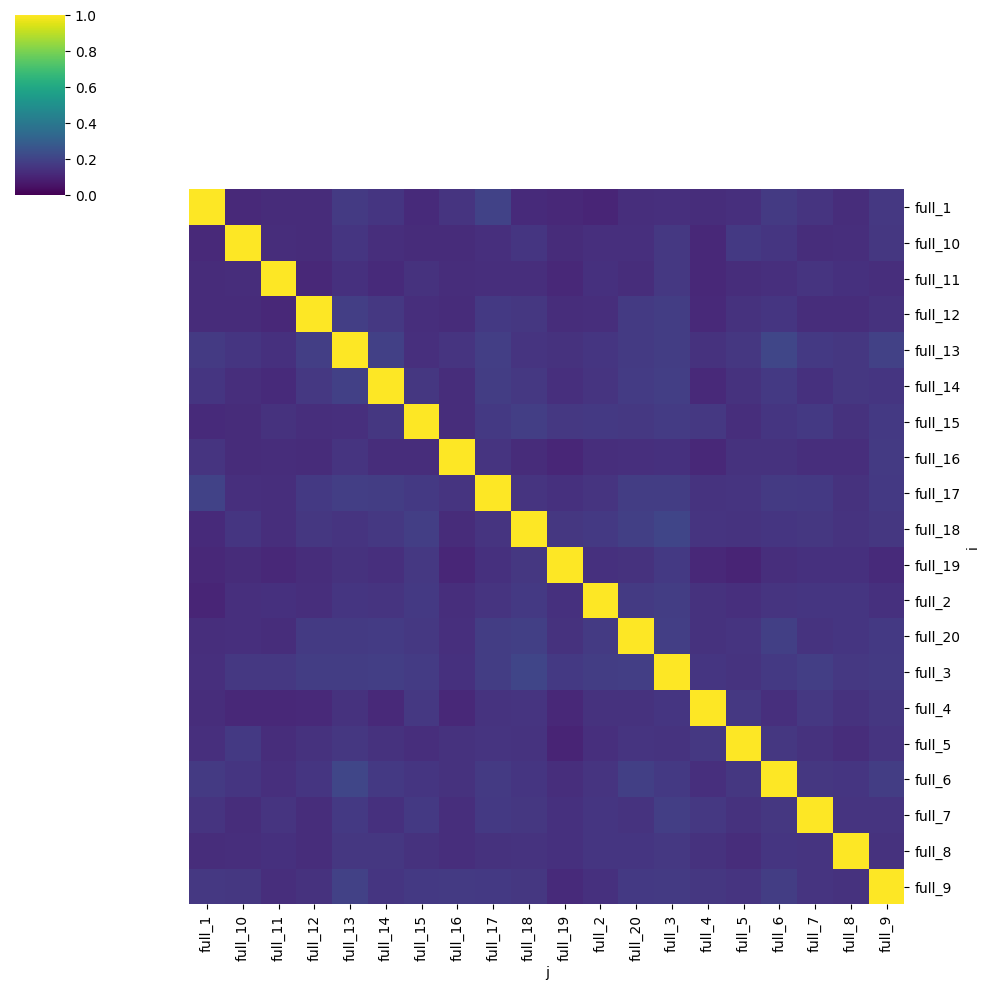

In [25]:
sns.clustermap(triplet_ji_df.pivot(index='i', columns='j', values='JI'), col_cluster=False, row_cluster=False, vmin=0, vmax=1, cmap='viridis')

In [26]:
## Peak info
peak_info = pd.read_csv(('/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/archr/tf_pilot/batch1/ipsc/all_peaks_info.txt'), sep='\t')

In [27]:
grn_comb

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full
AHCTF1#chr10:114239233-114239733#CCDC186,AHCTF1#chr10:114239233-114239733#CCDC186,AHCTF1,chr10:114239233-114239733,CCDC186,+,+,AHCTF1#chr10:114239233-114239733,chr10:114239233-114239733#CCDC186,AHCTF1#CCDC186,1,3,1,1,1
AHCTF1#chr10:119178594-119179094#SFXN4,AHCTF1#chr10:119178594-119179094#SFXN4,AHCTF1,chr10:119178594-119179094,SFXN4,+,+,AHCTF1#chr10:119178594-119179094,chr10:119178594-119179094#SFXN4,AHCTF1#SFXN4,1,6,1,1,1
AHCTF1#chr12:103957068-103957568#HCFC2,AHCTF1#chr12:103957068-103957568#HCFC2,AHCTF1,chr12:103957068-103957568,HCFC2,+,+,AHCTF1#chr12:103957068-103957568,chr12:103957068-103957568#HCFC2,AHCTF1#HCFC2,1,1,1,1,1
AHCTF1#chr12:122266760-122267260#DIABLO,AHCTF1#chr12:122266760-122267260#DIABLO,AHCTF1,chr12:122266760-122267260,DIABLO,+,+,AHCTF1#chr12:122266760-122267260,chr12:122266760-122267260#DIABLO,AHCTF1#DIABLO,1,3,1,1,1
AHCTF1#chr13:46387165-46387665#RUBCNL,AHCTF1#chr13:46387165-46387665#RUBCNL,AHCTF1,chr13:46387165-46387665,RUBCNL,+,+,AHCTF1#chr13:46387165-46387665,chr13:46387165-46387665#RUBCNL,AHCTF1#RUBCNL,1,2,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN5A#chr9:104926379-104926879#NIPSNAP3B,ZSCAN5A#chr9:104926379-104926879#NIPSNAP3B,ZSCAN5A,chr9:104926379-104926879,NIPSNAP3B,+,+,ZSCAN5A#chr9:104926379-104926879,chr9:104926379-104926879#NIPSNAP3B,ZSCAN5A#NIPSNAP3B,1,1,1,1,6
ZSCAN5A#chr9:128412332-128412832#SWI5,ZSCAN5A#chr9:128412332-128412832#SWI5,ZSCAN5A,chr9:128412332-128412832,SWI5,-,+,ZSCAN5A#chr9:128412332-128412832,chr9:128412332-128412832#SWI5,ZSCAN5A#SWI5,1,1,1,1,6
ZSCAN5A#chr9:129175718-129176218#SH3GLB2,ZSCAN5A#chr9:129175718-129176218#SH3GLB2,ZSCAN5A,chr9:129175718-129176218,SH3GLB2,-,+,ZSCAN5A#chr9:129175718-129176218,chr9:129175718-129176218#SH3GLB2,ZSCAN5A#SH3GLB2,1,8,1,1,6
ZSCAN5A#chr9:129568952-129569452#ASB6,ZSCAN5A#chr9:129568952-129569452#ASB6,ZSCAN5A,chr9:129568952-129569452,ASB6,-,+,ZSCAN5A#chr9:129568952-129569452,chr9:129568952-129569452#ASB6,ZSCAN5A#ASB6,1,8,1,1,6


In [28]:
x = pd.merge(grn_comb, peak_info[['name', 'peakType']].rename(columns={'name':'Region'}), on='Region', how='left')
x.index = grn_comb.index.copy()
grn_comb = x.copy()

In [29]:
grn_comb

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full,peakType
AHCTF1#chr10:114239233-114239733#CCDC186,AHCTF1#chr10:114239233-114239733#CCDC186,AHCTF1,chr10:114239233-114239733,CCDC186,+,+,AHCTF1#chr10:114239233-114239733,chr10:114239233-114239733#CCDC186,AHCTF1#CCDC186,1,3,1,1,1,Exonic
AHCTF1#chr10:119178594-119179094#SFXN4,AHCTF1#chr10:119178594-119179094#SFXN4,AHCTF1,chr10:119178594-119179094,SFXN4,+,+,AHCTF1#chr10:119178594-119179094,chr10:119178594-119179094#SFXN4,AHCTF1#SFXN4,1,6,1,1,1,Promoter
AHCTF1#chr12:103957068-103957568#HCFC2,AHCTF1#chr12:103957068-103957568#HCFC2,AHCTF1,chr12:103957068-103957568,HCFC2,+,+,AHCTF1#chr12:103957068-103957568,chr12:103957068-103957568#HCFC2,AHCTF1#HCFC2,1,1,1,1,1,Intronic
AHCTF1#chr12:122266760-122267260#DIABLO,AHCTF1#chr12:122266760-122267260#DIABLO,AHCTF1,chr12:122266760-122267260,DIABLO,+,+,AHCTF1#chr12:122266760-122267260,chr12:122266760-122267260#DIABLO,AHCTF1#DIABLO,1,3,1,1,1,Promoter
AHCTF1#chr13:46387165-46387665#RUBCNL,AHCTF1#chr13:46387165-46387665#RUBCNL,AHCTF1,chr13:46387165-46387665,RUBCNL,+,+,AHCTF1#chr13:46387165-46387665,chr13:46387165-46387665#RUBCNL,AHCTF1#RUBCNL,1,2,1,1,1,Exonic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN5A#chr9:104926379-104926879#NIPSNAP3B,ZSCAN5A#chr9:104926379-104926879#NIPSNAP3B,ZSCAN5A,chr9:104926379-104926879,NIPSNAP3B,+,+,ZSCAN5A#chr9:104926379-104926879,chr9:104926379-104926879#NIPSNAP3B,ZSCAN5A#NIPSNAP3B,1,1,1,1,6,Intronic
ZSCAN5A#chr9:128412332-128412832#SWI5,ZSCAN5A#chr9:128412332-128412832#SWI5,ZSCAN5A,chr9:128412332-128412832,SWI5,-,+,ZSCAN5A#chr9:128412332-128412832,chr9:128412332-128412832#SWI5,ZSCAN5A#SWI5,1,1,1,1,6,Intronic
ZSCAN5A#chr9:129175718-129176218#SH3GLB2,ZSCAN5A#chr9:129175718-129176218#SH3GLB2,ZSCAN5A,chr9:129175718-129176218,SH3GLB2,-,+,ZSCAN5A#chr9:129175718-129176218,chr9:129175718-129176218#SH3GLB2,ZSCAN5A#SH3GLB2,1,8,1,1,6,Exonic
ZSCAN5A#chr9:129568952-129569452#ASB6,ZSCAN5A#chr9:129568952-129569452#ASB6,ZSCAN5A,chr9:129568952-129569452,ASB6,-,+,ZSCAN5A#chr9:129568952-129569452,chr9:129568952-129569452#ASB6,ZSCAN5A#ASB6,1,8,1,1,6,Distal


In [30]:
grn_comb.to_csv((work_dir + 'eregulon_metadata_full_20runs_combined.csv'))

In [31]:
grn_comb_high_conf

,Triplet,TF,Region,Gene,TF2G_sign,R2G_sign,TF2R,R2G,TF2G,n_called_triplet_full,n_called_R2G_full,n_called_TF2G_full,n_called_TF2R_full,n_called_tf_full
ARID3A#chr11:107916525-107917025#RAB39A,ARID3A#chr11:107916525-107917025#RAB39A,ARID3A,chr11:107916525-107917025,RAB39A,-,+,ARID3A#chr11:107916525-107917025,chr11:107916525-107917025#RAB39A,ARID3A#RAB39A,6,6,6,6,12
ARID3A#chr11:64356450-64356950#GPR137,ARID3A#chr11:64356450-64356950#GPR137,ARID3A,chr11:64356450-64356950,GPR137,+,+,ARID3A#chr11:64356450-64356950,chr11:64356450-64356950#GPR137,ARID3A#GPR137,7,9,7,7,12
ARID3A#chr12:2691652-2692152#ITFG2,ARID3A#chr12:2691652-2692152#ITFG2,ARID3A,chr12:2691652-2692152,ITFG2,-,+,ARID3A#chr12:2691652-2692152,chr12:2691652-2692152#ITFG2,ARID3A#ITFG2,5,9,6,5,12
ARID3A#chr12:2944628-2945128#ITFG2,ARID3A#chr12:2944628-2945128#ITFG2,ARID3A,chr12:2944628-2945128,ITFG2,-,+,ARID3A#chr12:2944628-2945128,chr12:2944628-2945128#ITFG2,ARID3A#ITFG2,6,6,6,6,12
ARID3A#chr12:57456037-57456537#INHBE,ARID3A#chr12:57456037-57456537#INHBE,ARID3A,chr12:57456037-57456537,INHBE,+,+,ARID3A#chr12:57456037-57456537,chr12:57456037-57456537#INHBE,ARID3A#INHBE,5,5,7,5,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10#chrX:48958188-48958688#TFE3,ZSCAN10,chrX:48958188-48958688,TFE3,+,+,ZSCAN10#chrX:48958188-48958688,chrX:48958188-48958688#TFE3,ZSCAN10#TFE3,9,11,9,10,19
ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10#chrX:49002006-49002506#TFE3,ZSCAN10,chrX:49002006-49002506,TFE3,+,+,ZSCAN10#chrX:49002006-49002506,chrX:49002006-49002506#TFE3,ZSCAN10#TFE3,7,8,9,7,19
ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10#chrX:49073807-49074307#TFE3,ZSCAN10,chrX:49073807-49074307,TFE3,+,+,ZSCAN10#chrX:49073807-49074307,chrX:49073807-49074307#TFE3,ZSCAN10#TFE3,7,7,9,7,19
ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10#chrX:49101053-49101553#TFE3,ZSCAN10,chrX:49101053-49101553,TFE3,+,+,ZSCAN10#chrX:49101053-49101553,chrX:49101053-49101553#TFE3,ZSCAN10#TFE3,5,5,9,5,19


In [32]:
grn_comb_high_conf.to_csv((work_dir + 'eregulon_metadata_full_20runs_combined_min5recall.csv'))